# Sephora Skincare, Part 2: Who Is Underserved, and Does Price Buy Satisfaction?
**Author:** Rhiana Le · **Input:** `reviews_clean.parquet` (created by notebook 01: one row per distinct review)

**KPI:** detractor rate = share of reviews with 1–2 stars (chosen in notebook 01).

- **Q2:** Are some customer segments (skin type, skin tone) systematically less satisfied?
- **Q3:** Do more expensive products leave fewer customers unhappy?

In [3]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
pd.set_option('display.width', 200)
df = pd.read_parquet('reviews_clean.parquet')
print(f'{len(df):,} reviews | overall detractor rate {df.detractor.mean():.1%}')
INK, INK2, GRID, BG = '#0b0b0b', '#52514e', '#e6e5e0', '#fcfcfb'
def style(ax):
    ax.set_facecolor(BG); ax.tick_params(colors=INK2); ax.grid(axis='y', color=GRID, lw=0.6); ax.set_axisbelow(True)
    for s in ['top','right']: ax.spines[s].set_visible(False)

971,390 reviews | overall detractor rate 10.4%


## Q2a. Skin type

In [4]:
st = df.dropna(subset=['skin_type'])
overall = st.groupby('skin_type').detractor.agg(rate='mean', reviews='size')
overall['share_of_reviewers'] = overall.reviews / overall.reviews.sum()
overall.assign(rate=lambda d: (d.rate*100).round(1), share_of_reviewers=lambda d: (d.share_of_reviewers*100).round(1))

,rate,reviews,share_of_reviewers
skin_type,,,
combination,9.9,480204,55.4
dry,10.7,163835,18.9
normal,10.8,116713,13.5
oily,10.9,106155,12.2


In [5]:
by_cat = st.pivot_table(index='secondary_category', columns='skin_type', values='detractor', aggfunc='mean')*100
counts = st.pivot_table(index='secondary_category', columns='skin_type', values='detractor', aggfunc='size')
by_cat = by_cat[counts.min(axis=1) >= 500].round(1)
by_cat.assign(spread_pp=by_cat.max(axis=1) - by_cat.min(axis=1)).sort_values('spread_pp', ascending=False)

skin_type,combination,dry,normal,oily,spread_pp
secondary_category,,,,,
Self Tanners,14.9,16.4,18.8,14.4,4.4
Wellness,11.9,11.2,14.1,14.6,3.4
Sunscreen,12.6,14.0,14.8,14.2,2.2
Masks,9.1,10.2,10.6,8.6,2.0
Lip Balms & Treatments,10.6,12.3,11.8,10.9,1.7
Treatments,9.4,10.2,10.1,11.1,1.7
High Tech Tools,14.2,13.8,15.2,13.7,1.5
Moisturizers,9.3,10.2,9.7,10.6,1.3
Value & Gift Sets,9.8,10.7,11.1,10.6,1.3


**Result: skin type is not a major driver.** Across all skincare, detractor rates differ by only ~1 pp between skin types (9.9%–10.9%). Within most categories the spread is 1–2 pp. The exceptions are Self Tanners and Wellness, where it reaches 3–4 pp.

Two cautions:
- **Self-selection.** 55% of reviewers say they have *combination* skin. Skin type is self-reported, and many people pick "combination" as a default, so this field is a noisy segment label.
- **A metric I tried and rejected.** I first counted "well-rated products per skin type." That count is biased: products need enough reviews from a skin type to qualify, so the largest segment (combination) automatically looks best served. I dropped it rather than report a misleading number.

## Q2b. Skin tone: the sunscreen white-cast problem
In notebook 01, white cast came up as a sunscreen complaint. White cast is far more visible on darker skin, so I tested whether it hits those customers harder.

In [6]:
tone_order = ['fairLight','fair','light','lightMedium','medium','mediumTan','tan','deep']
ss = df[df.secondary_category == 'Sunscreen'].copy()
ss['mentions_white_cast'] = ss.review_text.fillna('').str.lower().str.contains(r'white ?cast|ashy|leaves? (?:a )?white')
det = ss[ss.detractor == 1]
tone = pd.DataFrame({
    'sunscreen_reviews': ss.groupby('skin_tone').size(),
    'detractor_rate_%': ss.groupby('skin_tone').detractor.mean()*100,
    'detractors_citing_white_cast_%': det.groupby('skin_tone').mentions_white_cast.mean()*100,
    'n_detractors': det.groupby('skin_tone').size()}).reindex(tone_order)
tone.round(1)

,sunscreen_reviews,detractor_rate_%,detractors_citing_white_cast_%,n_detractors
skin_tone,,,,
fairLight,2157,16.6,16.2,358.0
fair,7764,13.9,14.5,1077.0
light,10260,13.3,12.6,1369.0
lightMedium,7808,12.7,16.2,988.0
medium,2861,12.0,21.0,343.0
mediumTan,2525,13.5,20.3,340.0
tan,1350,13.3,29.4,180.0
deep,842,13.9,36.8,117.0


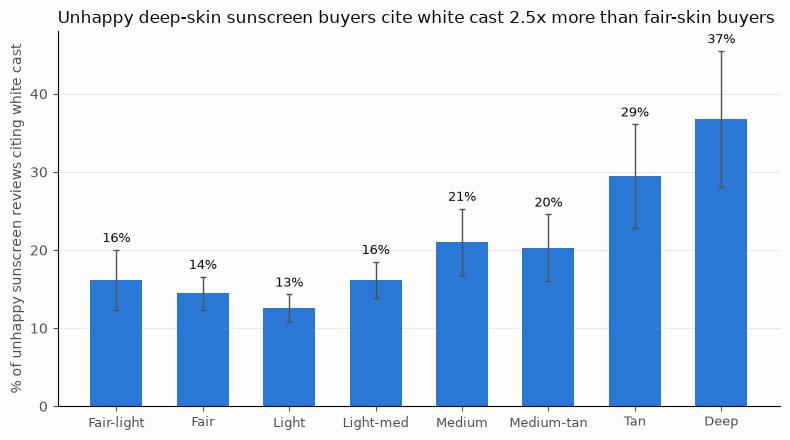

In [7]:
t = tone.dropna()
p = t['detractors_citing_white_cast_%']/100
ci = 1.96*np.sqrt(p*(1-p)/t.n_detractors)*100
fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=BG); style(ax)
labels = ['Fair-light','Fair','Light','Light-med','Medium','Medium-tan','Tan','Deep']
ax.bar(labels, t['detractors_citing_white_cast_%'], yerr=ci, width=0.6, color='#2a78d6',
       error_kw=dict(ecolor=INK2, lw=1, capsize=2))
for x, (v, c) in enumerate(zip(t['detractors_citing_white_cast_%'], ci)):
    ax.text(x, v + c + 1, f'{v:.0f}%', ha='center', fontsize=9, color=INK)
ax.set_ylabel('% of unhappy sunscreen reviews citing white cast', color=INK2)
ax.set_title('Unhappy deep-skin sunscreen buyers cite white cast 2.5x more than fair-skin buyers', loc='left', fontsize=12, color=INK)
ax.set_ylim(0, 48); plt.xticks(fontsize=9)
plt.tight_layout(); plt.savefig('fig_q2_sunscreen_white_cast.png', dpi=200); plt.show()

In [8]:
rep = df.skin_tone.value_counts(normalize=True)*100
print('Share of all skincare reviews by skin tone (%):'); print(rep.round(1).head(10).to_string())
print(f"\nTan + deep + rich + dark combined: {rep.reindex(['tan','deep','rich','dark']).sum():.1f}%")

Share of all skincare reviews by skin tone (%):
skin_tone
light          28.9
fair           22.5
lightMedium    21.2
medium          7.6
mediumTan       6.7
fairLight       6.1
tan             3.6
deep            2.2
rich            0.6
olive           0.2

Tan + deep + rich + dark combined: 6.5%


**Result: a hidden fit problem.**
- Among unhappy sunscreen reviewers, the share citing white cast rises steadily with skin depth: **~15% for fair skin → ~37% for deep skin.** (The deep-skin estimate rests on 117 detractor reviews, so its confidence interval is wide, roughly ±9 pp, but it stays far above the fair-skin level.)
- Overall sunscreen detractor rates are similar across tones (~12–17%). So the *average* hides the fact that deeper-skinned customers are unhappy for a *different, fixable* reason.
- **The rating is mostly written by lighter-skinned customers.** Only about 6.5% of skincare reviews come from tan, deep, rich or dark skin tones. A sunscreen's star rating therefore mostly reflects how it looks on light skin, which is exactly where white cast is least visible.

**Recommendation:** add a "no white cast / sheer on deep skin" attribute and let shoppers filter reviews by skin tone on sunscreen pages. This is a product-page fix, so it doesn't require new inventory.

## Q3. Does price buy satisfaction?

In [9]:
df['tier'] = pd.cut(df.prod_price, [0, 25, 50, 100, 1e4], labels=['<$25','$25–50','$50–100','$100+'])
(df.groupby('tier', observed=True).detractor.agg(rate='mean', reviews='size')
   .assign(rate=lambda d: (d.rate*100).round(1)))

,rate,reviews
tier,,
<$25,11.6,200600
$25–50,10.5,424121
$50–100,9.3,293310
$100+,10.0,53359


Cheaper products show more detractors. But this could be a **category-mix effect**: maybe cheap products are mostly lip balms and expensive ones are mostly serums. So I compare tiers **within** each category.

In [10]:
within = df.pivot_table(index='secondary_category', columns='tier', values='detractor', aggfunc='mean', observed=True)*100
n = df.pivot_table(index='secondary_category', columns='tier', values='detractor', aggfunc='size', observed=True)
within[n.min(axis=1) >= 500].round(1)

tier,<$25,$25–50,$50–100,$100+
secondary_category,,,,
Cleansers,11.4,9.5,7.3,3.3
Eye Care,16.1,13.3,9.9,10.3
High Tech Tools,12.9,11.4,21.1,12.9
Masks,10.6,8.2,10.3,10.2
Moisturizers,9.8,9.7,10.1,9.8
Treatments,14.0,10.1,7.8,10.1
Value & Gift Sets,10.3,10.7,9.6,14.7


In [11]:
# Sanity check: how many distinct products sit behind each cell?
df.pivot_table(index='secondary_category', columns='tier', values='product_id', aggfunc='nunique', observed=True).loc[within[n.min(axis=1) >= 500].index]

tier,<$25,$25–50,$50–100,$100+
secondary_category,,,,
Cleansers,89.0,214.0,40.0,2.0
Eye Care,16.0,57.0,92.0,19.0
High Tech Tools,15.0,11.0,16.0,33.0
Masks,57.0,45.0,53.0,9.0
Moisturizers,52.0,167.0,221.0,79.0
Treatments,90.0,107.0,186.0,64.0
Value & Gift Sets,24.0,75.0,49.0,21.0


In [12]:
sample = df.dropna(subset=['skin_type', 'prod_price']).sample(300_000, random_state=1)
sample['log2_price'] = np.log2(sample.prod_price)
model = smf.logit('detractor ~ log2_price + C(secondary_category) + C(skin_type)', data=sample).fit(disp=0)
or_, lo, hi = np.exp(model.params['log2_price']), *np.exp(model.conf_int().loc['log2_price'])
print(f'Odds ratio per doubling of price: {or_:.3f}  (95% CI {lo:.3f}–{hi:.3f})')
print(f'-> each doubling of price is associated with ~{(1-or_)*100:.0f}% lower odds of a 1–2 star review, holding category and skin type fixed')

Odds ratio per doubling of price: 0.864  (95% CI 0.853–0.875)
-> each doubling of price is associated with ~14% lower odds of a 1–2 star review, holding category and skin type fixed


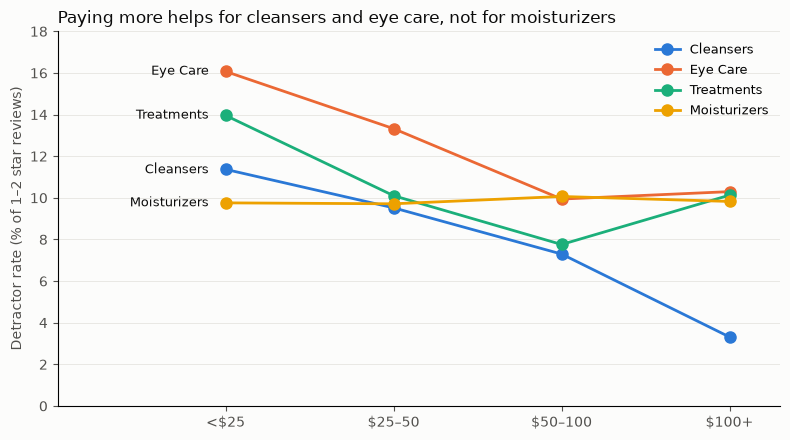

In [13]:
cats = ['Cleansers', 'Eye Care', 'Treatments', 'Moisturizers']
colors = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
tiers = list(within.columns)
fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=BG); style(ax)
for c, col in zip(cats, colors):
    ax.plot(tiers, within.loc[c], color=col, lw=2, marker='o', ms=8, label=c)
    ax.text(-0.1, within.loc[c].iloc[0], c, color=INK, fontsize=9, va='center', ha='right')
ax.set_ylabel('Detractor rate (% of 1–2 star reviews)', color=INK2)
ax.set_title('Paying more helps for cleansers and eye care, not for moisturizers', loc='left', fontsize=12, color=INK)
ax.set_xlim(-1.0, len(tiers)-1+0.3); ax.set_ylim(0, 18)
ax.legend(frameon=False, loc='upper right', fontsize=9)
plt.tight_layout(); plt.savefig('fig_q3_price_within_category.png', dpi=200); plt.show()

**Result: price matters, but not everywhere.**
- Even after controlling for category and skin type, each **doubling of price is associated with ~14% lower odds** of a detractor review.
- The effect is strongest in **Cleansers** (11.4% at <$25 → 7.3% at $50–100; the 3.3% at $100+ comes from only **2 products**, so I don't rely on it), **Eye Care** (16.1% → ~10%) and **Treatments** (14.0% → 7.8% at $50–100).
- **Moisturizers are flat** (~10% at every price): a $20 moisturizer satisfies as well as a $100 one.
- **Diminishing returns:** across categories, $100+ products are not better than $50–100 products, and sometimes worse. High prices raise expectations.

**Why this might not be causal:** luxury buyers may differ from budget buyers (different expectations, more experience), premium brands may also invest more in formulation, and prices are from the 2023 scrape rather than the time of each review.

**Recommendation:**
- **Moisturizers:** budget options are a safe place to grow assortment and run promotions.
- **Eye care and treatments:** the under-$25 tier has the most unhappy customers, so these lines need stricter quality screening before onboarding.

## Summary for leadership
| Question | Answer | Action |
|---|---|---|
| Q1: Which KPI? | Stars and "recommend" move together (r = 0.97) | Track **detractor rate** |
| Q1: Where is dissatisfaction? | Self tanners, devices, sunscreen: 40–70% more detractors | Fit / product / value fixes by category |
| Q2: Skin type? | Small effect (~1 pp) and a noisy label | Don't segment merchandising by skin type alone |
| Q2: Skin tone? | Deep-skin sunscreen complaints are 2.5x more about white cast; ~6.5% of reviews come from tan-to-dark tones | "Sheer on deep skin" tags and review filters by skin tone |
| Q3: Price? | Doubling price ≈ 14% lower odds of a detractor; strong in cleansers and eye care, flat in moisturizers | Grow budget moisturizers; screen budget eye care and treatments |

**Next:** notebook 03, an interactive Tableau dashboard of these KPIs.